# N10LO: generation beyond published low-order formulas

This case generates both spectra at `p=10` and the first tensor running
$\alpha_1^t$ at `n=1,p=10`, hence $W=12$. Generated expressions are available in
[the equation documents](../../../results/README.md), separately from these validation checks.
The coefficients are generated numerical values, not asserted analytic constants.

There is no published order-ten coefficient table used as a target. Validation
therefore comes from independently solved equations, exact limits and formal
substitution identities.

![Convergence against independently integrated canonical modes](figures/mode_convergence.png)

Relative amplitude errors against independent scalar (darkgreen, solid) and tensor
(darkred, dashed) modes, for the nonconstant canonical background
$a(x)=x^{-1}\exp[-e(x^b-1)/b]$, $x=-k\eta$, $e=0.08$, $b=0.073$.
The reference is evaluated at $x=1$ and both polarizations are included for tensors.
The coefficient tests below check the formal SR order directly, even where
finite-parameter remainders happen to cancel.

## What is checked

- All 138 generated universal moments against a separately implemented linear mode and growing-pump solver, with two independent integration resolutions.
- All growing-pump polynomials by exact comparison before integration.
- Available Gamma/Mellin coefficients as mathematical oracles, with no literature table.
- Exact constant-`epsilon` Hankel amplitudes and remainder scaling for every `p=0,...,10`.
- Individual scalar and tensor parameter-Taylor coefficients through `p=10` for the nonconstant canonical background.
- Direct finite-parameter scalar and tensor modes at three background rescalings, with refined initial conditions, integration and freeze-out.
- The `n=1,p=10` consistency relation by exactly zero forward-substitution residual, correct weights, observable-only output, the zero-`r` limit and the constant-`epsilon` specialization.



In [1]:
# WG Edit: find the checkout independently of the notebook launch directory.
from pathlib import Path
import os, sys

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents]
            if (path / "source").is_dir() and (path / "pyproject.toml").is_file())
sys.path.insert(0, str(ROOT))
from validation.canonical_SRI.order_cases import saved_report, run_lo, run_low, run_high, lo_bell
from sri import spectra, consistency


## Run the validation

The saved execution is shown for the matching calculation sources. Set `RERUN=True` to regenerate and rerun all checks. N10LO takes several minutes.

In [2]:
# WG Edit: distinguish a fresh execution from a verified saved report.
RERUN = False
report = run_high() if RERUN else saved_report(10)
assert report["status"] == "passed"
print("Fresh execution" if RERUN else "Saved validation results")
print("All recorded checks passed.")

Saved validation results
All recorded checks passed.


## Independent order-ten checks

The production moments and the linear mode oracle are generated separately. The background-elimination check is an exact identity over the generated rational data, while the mode-coefficient comparisons are numerical tests.

In [3]:
# WG Edit: report explicit numerical coverage and the chosen observable relation.
modes = report["checks"]["independent_linear_modes"]
print(f"Independent moments checked: {modes['moments_checked']}")
print(f"Maximum scaled cross-method residual: {modes['maximum_scaled_cross_method_difference']:.3e}")
row = report["checks"]["consistency"]
print(f"n={row['n']}, p={row['p']}, W={row['W']}: exact residual "
      f"{row['exact_forward_substitution_residual']}; {row['terms']} terms")
errors = [max(row["relative_coefficient_differences"])
          for row in report["checks"]["physical_taylor"]["comparisons"]]
print(f"Independent physical Taylor coefficients: max relative residual {max(errors):.3e}")
case = report["checks"]["physical_modes"]["runs"][0]
for field in ("scalar", "tensor"):
    print(f"{field}, p=10: finite-parameter relative amplitude error "
          f"{case['relative_errors'][field+'10']:.3e}")
print("Generated equations: results/canonical_SRI/N10LO/N10LO.tex")

Independent moments checked: 138
Maximum scaled cross-method residual: 0.000e+00
n=1, p=10, W=12: exact residual 0; 617 terms
Independent physical Taylor coefficients: max relative residual 2.626e-16
scalar, p=10: finite-parameter relative amplitude error 1.940e-10
tensor, p=10: finite-parameter relative amplitude error 3.009e-10
Generated equations: results/canonical_SRI/N10LO/N10LO.tex


## Figure

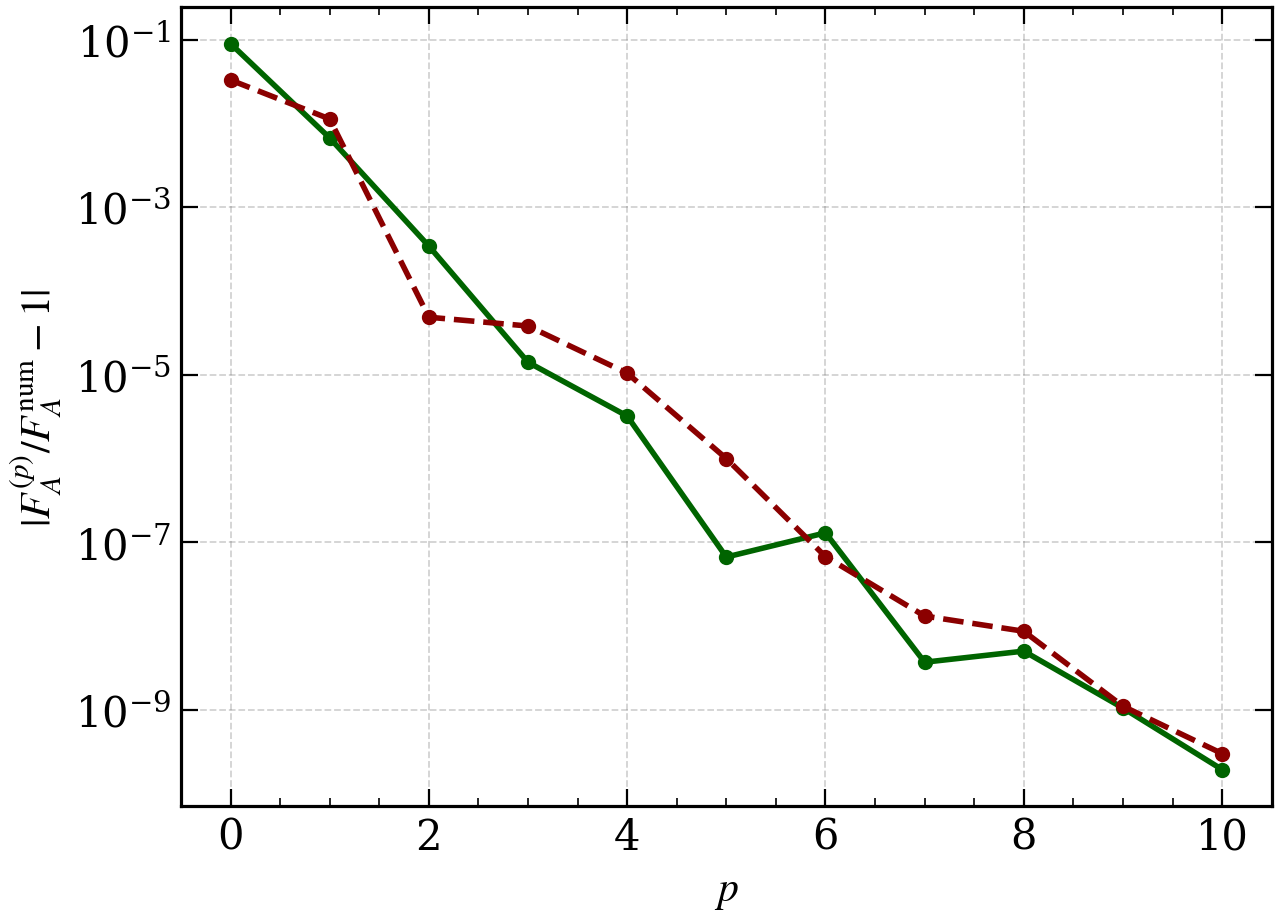

In [4]:
# WG Edit: display the saved scientific figure.
from IPython.display import Image, display
display(Image(filename=str(ROOT / "validation/canonical_SRI/N10LO/figures/mode_convergence.png")))

## Spectra

[Generated equations](../../../results/canonical_SRI/N10LO/N10LO.pdf) · [LaTeX source](../../../results/canonical_SRI/N10LO/N10LO.tex)